In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'True' # Оставляем, чтобы не падало ядро
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import torchvision
import torchvision.transforms as transforms
import torch
import torch.nn as nn
from torch.utils.data import DataLoader

In [2]:
root_path = r'C:\Users\PC\Desktop\python\convolutional'

raw_trainset = torchvision.datasets.CIFAR10(
    root=root_path, train=True, download=False,
    transform=transforms.ToTensor(),
)


In [3]:
# Загружаем все картинки в один тензор
all_images = torch.stack([img for img, _ in raw_trainset])  # (50000, 3, 32, 32)

mean = all_images.mean(dim=[0, 2, 3])   # (3,)
std  = all_images.std(dim=[0, 2, 3])    # (3,)

print("mean:", mean.tolist())
print("std: ", std.tolist())

cifar_mean = tuple(mean.tolist())
cifar_std = tuple(std.tolist())

mean: [0.491400808095932, 0.48215898871421814, 0.44653093814849854]
std:  [0.24703224003314972, 0.24348513782024384, 0.26158785820007324]


In [4]:
train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4), # доабвляет 4 пикселя и убирает 4 рандомных пикселя по периметру
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std),
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(cifar_mean, cifar_std),
])

trainset = torchvision.datasets.CIFAR10(
    root=root_path, train=True,  download=False, transform=train_transform
)
testset = torchvision.datasets.CIFAR10(
    root=root_path, train=False, download=False, transform=test_transform
)

train_loader = DataLoader(trainset, batch_size=64, shuffle=True,  num_workers=0)
test_loader  = DataLoader(testset,  batch_size=64, shuffle=False, num_workers=0)

# проверка
images, labels = next(iter(train_loader))
print(images.shape, images.dtype)   # картинка батч
print(labels.shape, labels.dtype)   # метки класса

torch.Size([64, 3, 32, 32]) torch.float32
torch.Size([64]) torch.int64


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


изображение torch.Size([3, 32, 32])
классы ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


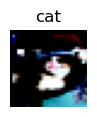

In [5]:
image, label = trainset[0]

print(f"изображение {image.shape}")
print(f"классы {trainset.classes}")

image, label = trainset[12332]
img_show = image.permute(1, 2, 0) # каналы последние

plt.figure(figsize=(1, 1))
plt.imshow(img_show)
plt.title(trainset.classes[label])
plt.axis('off')
plt.show()

# Функции тренировки теста

In [6]:
def train_one_epoch(model, train_set, opt, loss_function):
    model.train()

    total = 0
    total_correct_cnt = 0
    loss_value = 0

    for images, labels in tqdm(train_set):
        opt.zero_grad()

        logits = model(images)
        loss = loss_function(logits, labels)
        loss.backward()
        opt.step()

        loss_value += loss.item() * images.size(0)
        total += labels.size(0)
        total_correct_cnt += (logits.argmax(dim = 1) == labels).sum().item()

    return loss_value / total, total_correct_cnt / total

def test(model, test_set, loss_function):
    model.eval()

    total = 0
    total_correct_cnt = 0
    loss_value = 0

    with torch.no_grad():
        for images, labels in tqdm(test_set):
            logits = model(images)
            loss = loss_function(logits, labels)
            loss_value += loss.item() * images.size(0)

            total += labels.size(0)
            total_correct_cnt += (logits.argmax(dim = 1) == labels).sum().item()

    return loss_value / total, total_correct_cnt / total
            

In [7]:
class cnn_cifar(nn.Module):
    def __init__(self):
        super().__init__()

        self.block1 = nn.Sequential( # 3* 32 * 32
            nn.Conv2d(in_channels = 3, out_channels = 64, kernel_size = 3, padding = 1), # 64* 32 * 32
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.Conv2d(in_channels = 64, out_channels = 64, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)  # 64 * 16 * 16  
        )

        self.block2 = nn.Sequential( # 64 * 16 * 16  
            nn.Conv2d(in_channels = 64, out_channels = 128, kernel_size = 3, padding = 1), # 128 * 16 * 16  
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.Conv2d(in_channels = 128, out_channels = 128, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2) # 128 * 8 * 8
        )

        self.block3 = nn.Sequential( # 128 * 8 * 8
            nn.Conv2d(in_channels = 128, out_channels = 256, kernel_size = 3, padding = 1), # 256 * 16 * 16  
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.Conv2d(in_channels = 256, out_channels = 256, kernel_size = 3, padding = 1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2) # 256 * 4 * 4
        )
        
        self.classificator = nn.Sequential(
            nn.AdaptiveAvgPool2d(1), # 256 картинок 4 на 4, взять среднее каждой, получим 256 мерный вектор
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(256, 10)
        )

    def forward(self, input):
        x = self.block1(input)
        x = self.block2(x)
        x = self.block3(x)
        x = self.classificator(x)
        return x

In [8]:
model = cnn_cifar()
sum(list(p.numel() for p in model.parameters())) # всего параметров

1149770

In [9]:
model = cnn_cifar()

loss_func = nn.CrossEntropyLoss()

optimizer = torch.optim.AdamW(model.parameters(), lr= 0.001, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)



In [10]:
for epoch in range(1, 21):
    train_loss, train_accuracy = train_one_epoch(model, train_loader, optimizer, loss_func)
    test_loss, test_accuracy = test(model, test_loader, loss_func)
    scheduler.step()

    print(f"epoch {epoch}: "
      f"train loss {train_loss:.4f} acc {train_accuracy:.4f} | "
      f"test  loss {test_loss:.4f} acc {test_accuracy:.4f}")

100%|████████████████████████████████████████████████████████████████████████████████| 157/157 [00:21<00:00,  7.22it/s]


epoch 1: train loss 1.3154 acc 0.5219 | test  loss 1.4213 acc 0.5337


100%|████████████████████████████████████████████████████████████████████████████████| 157/157 [00:22<00:00,  7.13it/s]


epoch 2: train loss 0.8818 acc 0.6884 | test  loss 0.8112 acc 0.7240


100%|████████████████████████████████████████████████████████████████████████████████| 157/157 [00:24<00:00,  6.54it/s]


epoch 3: train loss 0.7129 acc 0.7512 | test  loss 0.8317 acc 0.7211


... (28 outputs left out)

100%|████████████████████████████████████████████████████████████████████████████████| 157/157 [00:19<00:00,  8.11it/s]


epoch 18: train loss 0.3190 acc 0.8921 | test  loss 0.3777 acc 0.8726


  3%|██                                                                               | 20/782 [00:07<04:32,  2.79it/s]


KeyboardInterrupt: 

In [11]:
torch.save(model.state_dict(), 'cnn_cifar_87.pth')
print("saved")

saved


In [13]:
model = cnn_cifar()                          # та же архитектура!
model.load_state_dict(torch.load('cnn_cifar_87.pth'))
model.eval()

C:\Users\PC\AppData\Local\Temp\ipykernel_4404\1178891086.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load('cnn_cifar_87.pth'))


cnn_cifar(
  (block1): Sequential(
    (0): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block2): Sequential(
    (0): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (block3): Sequential(
    (0): Conv2d(1

In [31]:
model2 = cnn_cifar()
model2.load_state_dict(torch.load('cnn_cifar_87.pth'))
model2.eval()
loss, acc = test(model2, test_loader, loss_func)
print(f"loaded model: test acc {acc:.4f}")   # должно быть ~0.873

C:\Users\PC\AppData\Local\Temp\ipykernel_4404\3965018865.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model2.load_state_dict(torch.load('cnn_cifar_87.pth'))
100%|████

loaded model: test acc 0.8734
